## Import libraries

In [144]:
import numpy as np # numpy
import math  # math
import time # time
import pandas as pd # Pandas

# Residual points generating
from pyDOE import lhs

# Import torch libraries
import torch
from torch import Tensor
import torch.autograd as autograd
import torch.optim as optim
import torch.nn as nn

# matplotlib for ploting
import matplotlib.pyplot as plt

# Saving data files
from numpy import asarray
from numpy import savetxt

## Random Seed Values

In [145]:
## Random seed values:
torch.set_default_dtype(torch.float)
torch.manual_seed(789)
np.random.seed(789)

## Check GPU

In [146]:
torch.cuda.empty_cache() # Empty the cache memory

# Saving the device name for gpu
device=torch.cuda.get_device_name()
print("Original Device Name:",device)

#
device=torch.device('cuda' if torch.cuda.is_available() else "cpu")
print(device)

Original Device Name: NVIDIA GeForce RTX 3060 Laptop GPU
cuda


## Generated data set for training the model

In [147]:
# Generate data x (position) from 0 to 1 (100 points)
x_data=np.linspace(0,1,100)[:,None]

# Generate data t(time) from 0 to 0.2sec (100 points)
t_data=np.linspace(0,0.2,100)[:,None]

In [148]:
# Generating mesh grid from data x and time t
X,T=np.meshgrid(x_data,t_data)

# Flatting the complete data set.
XT_Test=np.hstack((X.flatten()[:,None],T.flatten()[:,None]))

In [149]:
# Extending the domain
x_data_extended=np.linspace(-2.5,2.5,1000)[:,None]

# Flatting the extended domain
X_Extended,T=np.meshgrid(x_data_extended,t_data)

In [150]:
# Flatting the extended data set
xt_train=np.hstack((X_Extended.flatten()[:,None],T.flatten()[:,None]))

## Initial condition

In [151]:
# Initial Condition

Initial_xt=xt_train[0:1000,:]

Initial_xt_left=[]
Initial_xt_right=[]

for i in range(len(Initial_xt)):
    if Initial_xt[i,[0]]<=0.5:
        Initial_xt_left.append(Initial_xt[i])
    else:
        Initial_xt_right.append(Initial_xt[i])


#print(Initial_xt)
#print(Initial_xt_right)

# Rho, Velcocity, Pressure
Initial_left_Rho=[1]*(len(Initial_xt_left))
Initial_left_U=[0]*(len(Initial_xt_left))
Initial_left_P=[1]*(len(Initial_xt_left))

Initial_right_Rho=[0.125]*(len(Initial_xt_right))
Initial_right_U=[0]*(len(Initial_xt_right))
Initial_right_P=[0.1]*(len(Initial_xt_right))

# Converting the list to array
Initial_xt_left=np.array(Initial_xt_left)
Initial_xt_right=np.array(Initial_xt_right)
#print(Initial_xt_right)

Initial_left_Rho=np.array(Initial_left_Rho)[:,None]
Initial_left_U=np.array(Initial_left_U)[:,None]
Initial_left_P=np.array(Initial_left_P)[:,None]

Initial_left_Rho_U_P=np.hstack((Initial_left_Rho,Initial_left_U,Initial_left_P))


Initial_right_Rho=np.array(Initial_right_Rho)[:,None]
Initial_right_U=np.array(Initial_right_U)[:,None]
Initial_right_P=np.array(Initial_right_P)[:,None]

Initial_right_Rho_U_P=np.hstack((Initial_right_Rho,Initial_right_U,Initial_right_P))

## Boundary Condition

In [152]:
# Far field Condition

Boundary_left_far=[xt_train[i,:] for i in range(len(xt_train)) if xt_train[i,0]==-2.5]
Boundary_left_far=np.array(Boundary_left_far)

Boundary_right_far=[xt_train[i,:] for i in range(len(xt_train)) if xt_train[i,0]==2.5]
Boundary_right_far=np.array(Boundary_right_far)

# Density, Velocity, Pressure
Boundary_left_Rho_far=[1]*(len(Boundary_left_far))
Boundary_left_U_far=[0]*(len(Boundary_left_far))
Boundary_left_P_far=[1]*(len(Boundary_left_far))

Boundary_right_Rho_far=[0.125]*(len(Boundary_right_far))
Boundary_right_U_far=[0]*(len(Boundary_right_far))
Boundary_right_P_far=[0.1]*(len(Boundary_right_far))

# Converting the list data to the array 
Boundary_left_Rho_far=np.array(Boundary_left_Rho_far)[:,None]
Boundary_left_U_far=np.array(Boundary_left_U_far)[:,None]
Boundary_left_P_far=np.array(Boundary_left_P_far)[:,None]
Boundary_right_Rho_far=np.array(Boundary_right_Rho_far)[:,None]
Boundary_right_U_far=np.array(Boundary_right_U_far)[:,None]
Boundary_right_P_far=np.array(Boundary_right_P_far)[:,None]

# Horizonal stack the values
Boundary_left_Rho_U_P_far=np.hstack((Boundary_left_Rho_far,Boundary_left_U_far,Boundary_left_P_far))
Boundary_right_Rho_U_P_far=np.hstack((Boundary_right_Rho_far,Boundary_right_U_far,Boundary_right_P_far))

In [153]:
# Conditions at boundaries

Boundary_left=[XT_Test[i,:] for i in range(len(XT_Test)) if XT_Test[i,0]==0]
Boundary_left=np.array(Boundary_left)

Boundary_right=[XT_Test[i,:] for i in range(len(XT_Test)) if XT_Test[i,0]==1]
Boundary_right=np.array(Boundary_right)

# Density, Velocity, Pressure
Boundary_left_Rho=[1]*(len(Boundary_left))
Boundary_left_U=[0]*(len(Boundary_left))
Boundary_left_P=[1]*(len(Boundary_left))

Boundary_right_Rho=[0.125]*(len(Boundary_right))
Boundary_right_U=[0]*(len(Boundary_right))
Boundary_right_P=[0.1]*(len(Boundary_right))

# Convering the list data to the array
Boundary_left_Rho=np.array(Boundary_left_Rho)[:,None]
Boundary_left_U=np.array(Boundary_left_U)[:,None]
Boundary_left_P=np.array(Boundary_left_P)[:,None]
Boundary_right_Rho=np.array(Boundary_right_Rho)[:,None]
Boundary_right_U=np.array(Boundary_right_U)[:,None]
Boundary_right_P=np.array(Boundary_right_P)[:,None]

Boundary_left_Rho_U_P=np.hstack((Boundary_left_Rho,Boundary_left_U,Boundary_left_P))
Boundary_right_Rho_U_P=np.hstack((Boundary_right_Rho,Boundary_right_U,Boundary_right_P))

## Stacking the values

In [154]:
# Vertically stack the values
Initial_condition=np.vstack((Initial_xt_left,Initial_xt_right))
Initial_condition_Rho_U_P=np.vstack((Initial_left_Rho_U_P,Initial_right_Rho_U_P))

# Vertically stack the values
Boundary_condition=np.vstack((Boundary_left,Boundary_right,Boundary_left_far,Boundary_right_far))
Boundary_condition_Rho_U_P=np.vstack((Boundary_left_Rho_U_P,Boundary_right_Rho_U_P,Boundary_left_Rho_U_P_far,Boundary_right_Rho_U_P_far))

In [155]:
#X_training=pd.read_csv('D:\\THESIS_WORK_FINAL\\FINAL CODES\\SOD_SHOCK_TUBE\\W-PINNS-DE\\X_train.csv')
#U_training=pd.read_csv("D:\THESIS_WORK_FINAL\FINAL CODES\SOD_SHOCK_TUBE\W-PINNS-DE\\U_train.csv")
                       
#

# vstack the boundary and initial values
X_train=np.vstack((Initial_condition,Boundary_condition,X_training))
U_train=np.vstack((Initial_condition_Rho_U_P,Boundary_condition_Rho_U_P,U_training))


#print("X_train: ",X_train.shape)
#print("U_train: ",U_train.shape)

#print("X_training:",X_training.shape)
#print("U_training:",U_training.shape)

## Upper and lower limit of scaling

In [156]:
lb=xt_train[0]
ub=xt_train[-1]
print(lb,ub)

##
lb_L=xt_train[0]
ub_L=np.array([0, 0.2])

lb_M=np.array([0,0])
ub_M=np.array([1,0.2])

lb_R=np.array([1,0])
ub_R=np.array([2.5,0.2])
#print(lb_R)

[-2.5  0. ] [2.5 0.2]


## Generate training data points

In [157]:
Nu=200 # Training points
Nf=5000 # Residual points

# Modified domain Residual Points
Nf_L=300
Nf_R=200

# Generated domain
XT_f_train_M=lb_M+(ub_M-lb_M)*lhs(2,Nf)
XT_f_train_L=lb_L+(ub_L-lb_L)*lhs(2,Nf_L)
XT_f_train_R=lb_R+(ub_R-lb_R)*lhs(2,Nf_R)

In [158]:
# Random selection of training points
idx=np.random.choice(X_train.shape[0],Nu,replace=False)
#print(xt_train.shape)

# Taking the random traing values
XT_train=X_train[idx,:]
U_train=U_train[idx,:]

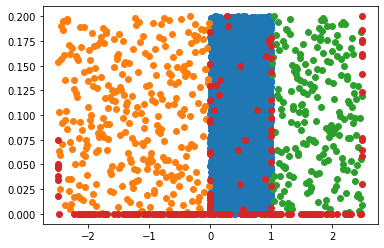

In [159]:
# Ploting the modified domain
# Traing points=200
# Residual points=2000
# Foreign points=500

#print(XT_train.shape)
#print(U_train.shape)

plt.scatter(XT_f_train_M[:,0],XT_f_train_M[:,1])
plt.scatter(XT_f_train_L[:,0],XT_f_train_L[:,1])
plt.scatter(XT_f_train_R[:,0],XT_f_train_R[:,1])
plt.scatter(XT_train[:,0],XT_train[:,1])

In [160]:
# Vertically stack the values
XT_f_train=np.vstack((XT_f_train_L,XT_f_train_M,XT_f_train_R))

In [161]:
#savetxt('XT_f_train_M',XT_f_train_M,delimiter=',')
#savetxt('XT_f_train_L',XT_f_train_L,delimiter=',')
#savetxt('XT_f_train_R',XT_f_train_R,delimiter=',')
#savetxt('XT_train',XT_train,delimiter=',')

## Converting the float values to the Tensor Torch

In [162]:
XT_train=torch.from_numpy(XT_train).float().to(device)
U_train=torch.from_numpy(U_train).float().to(device)
XT_f_train=torch.from_numpy(XT_f_train).float().to(device)

f_hat=torch.zeros(XT_f_train.shape[0],1).to(device)

In [163]:
print(XT_train.shape)
print(U_train.shape)
print(XT_f_train.shape)
print(f_hat.shape)

torch.Size([200, 2])
torch.Size([200, 3])
torch.Size([5500, 2])
torch.Size([5500, 1])


## W-PINNs-DE

In [164]:
class SOD_SHOCK_TUBE(nn.Module):
    
    def __init__(self,layers):
        
        # Inherentance: taking the function form nn.Module
        super().__init__()
        
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the Loss function as Mean square Loss function
        self.Loss_function=nn.MSELoss(reduction='mean')
        
        # Generating the ModuleList
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1]) for i in range(len(layers)-1)])
        
        # Iteration
        self.iter=0
        
        # Defining the Xavier normal for weight and zero as bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=5/3)
            nn.init.zeros_(self.linears[i].bias.data)
    
    # Forward Pass function
    def forward(self,X):
        
        # Check whether the X data is Tensor or not
        if torch.is_tensor(X)!=True:
            X=torch.from_numpy(X)
            
        # Converting the Boundary values (min,max)
        L_b=torch.from_numpy(lb).float().to(device)
        U_b=torch.from_numpy(ub).float().to(device)
        
        # Feature Scale
        X=(X-L_b)/(U_b-L_b)
        
        a=X.float()
        
        Rho_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        U_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        P_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        
        # Forward Pass loop upto the second last layer 
        for i in range(len(layers)-2):
            z1=self.linears[i](Rho_Pred)
            z2=self.linears[i](U_Pred)
            z3=self.linears[i](P_Pred)
            
            Rho_Pred=self.activation(z1)
            U_Pred=self.activation(z2)
            P_Pred=self.activation(z3)
            
        # Pass the data to the last layer
        Rho_Pred=self.linears[-1](Rho_Pred)
        U_Pred=self.linears[-1](U_Pred)
        P_Pred=self.linears[-1](P_Pred)
        
        # a=[Rho, U, P]
        a=torch.cat((Rho_Pred,U_Pred,P_Pred),1)
        
        return a
    
    # Boundary loss function
    def LossBC(self,X,Y):
        
        # Forward Pass the X data for boundary and Initial Values
        Pred_val=self.forward(X)
        
        PRED_RHO=Pred_val[:,[0]]
        PRED_U=Pred_val[:,[1]]
        PRED_P=Pred_val[:,[2]]
        
        # Calculating the MSE Loss of predicted data
        Loss_Rho=self.Loss_function(PRED_RHO,Y[:,[0]])
        Loss_U=self.Loss_function(PRED_U,Y[:,[1]])
        Loss_P=self.Loss_function(PRED_P,Y[:,[2]])
        
        # total Boundary and Initial Loss
        Loss_BC=Loss_Rho+Loss_U+Loss_P
        
        return Loss_BC
    
    # PDE loss function
    def LossPDE(self,xy_to_train_f):
        
        # Gamma for air
        gamma=1.4
        
        g=xy_to_train_f.clone()
        
        g.requires_grad=True
        
        # Forward Pass the the data xy_to_train_f
        RHO_U_P=self.forward(g)
        
        RHO=RHO_U_P[:,[0]]
        U=RHO_U_P[:,[1]]
        P=RHO_U_P[:,[2]]
        
        # Calculating the gradient of the calculated RHO
        RHO_xt=autograd.grad(RHO,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        RHO_x=RHO_xt[:,[0]]
        RHO_t=RHO_xt[:,[1]]
        
        # Calculating the gradient of the calculated U
        U_xt=autograd.grad(U,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        U_x=U_xt[:,[0]]
        U_t=U_xt[:,[1]]
        
        # Calculating the gradient of the calculated P
        P_xt=autograd.grad(P,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        P_x=P_xt[:,[0]]
        P_t=P_xt[:,[1]]
        
        # Three eqution, Conservation of mass, momentum and energy
        F1=RHO_t + U*(RHO_x) + RHO*(U_x)
        F2=RHO*(U_t + U*(U_x)) + P_x
        F3=P_t + gamma*P*(U_x) + U*(P_x)
        
        # Equation 
        # Entroypy calculation
        
        # MSE Loss function Calculation 
        LossF1=self.Loss_function(F1,f_hat)
        LossF2=self.Loss_function(F2,f_hat)
        LossF3=self.Loss_function(F3,f_hat)
        #LossF4=self.Loss_function(F4,f_hat)
        
        # Total PDE LOSS
        LossPDE=LossF1+LossF2+LossF3
        
        return LossPDE
    
    # Total loss function
    def Loss(self,X,Y,xy_to_train_f):
        
        # Calling the Boundary Loss function
        Loss1=self.LossBC(X,Y)
        
        # Calling the PDE Loss function
        Loss2=self.LossPDE(xy_to_train_f)
        
        # Total MSE LOSS--> Sum of the PDE_LOSS + BC_LOSS
        Total_Loss_W=Loss1*10 + Loss2*0.1
        
        Total_Loss=Loss1 + Loss2
        
        # Saving the Data
        #file1=open('BC_LOSS.txt','a')
        #file1.write(str(Loss1.item())+'\n')
        #file1.close()
        
        #file1=open('PDE_LOSS.txt','a')
        #file1.write(str(Loss2.item())+'\n')
        #file1.close()
        
        #file3=open('TOTAL_LOSS_W_PINNs.txt','a')
        #file3.write(str(Total_Loss_W.item())+'\n')
        #file3.close()
        
        #file4=open('TOTAL_LOSS.txt','a')
        #file4.write(str(Total_Loss.item())+'\n')
        #file4.close()
        
        # Return total loss value
        return Total_Loss_W
    
    # Closure function 
    def closure(self):
        
        # Initial taking the gradient as zero
        optimizer.zero_grad()
        
        # Calling the Loss function
        Loss=self.Loss(XT_train,U_train,XT_f_train)
        
        # Backprop
        Loss.backward()
        
        # Iteration +=1
        self.iter+=1
        
        # Print the Loss at every 100 iteration
        if self.iter%100==0:
            print(Loss)
        
        # Return the loss value 
        return Loss
    
    # Test function 
    def Test(self,Test_data):
        # Forward pass the test data
        Rho_P_U=self.forward(Test_data)
        # detach the values cpu
        Rho_P_U=Rho_P_U.detach().cpu().numpy()
        
        Rho_Pred=Rho_P_U[:,[0]]
        P_Pred=Rho_P_U[:,[1]]
        U_Pred=Rho_P_U[:,[2]]
        
        # Return the predicted values=[Rho,Pressure,Velocity]
        return [Rho_Pred,P_Pred,U_Pred]
        

In [168]:
layers=[2,80,80,80,80,3] # No of neurons in each layer

# Object of the class
SD=SOD_SHOCK_TUBE(layers)

# Passing the object to the device
SD.to(device)

params=list(SD.parameters())

# Optimization methods
optimizer=optim.LBFGS(SD.parameters(),lr=0.1,max_iter=50000)

# Training time for the optimization
start_time1=time.time()
optimizer.step(SD.closure)
Training_time1=time.time()-start_time1

#
# # Optimization methods
# optimizer=optim.LBFGS(SD.parameters(),lr=0.0001,max_iter=10000)

# # Training time for the optimization
# start_time2=time.time()
# optimizer.step(SD.closure)
# Training_time2=time.time()-start_time2


print("Training Time:- ", Training_time1)#+Training_time2)

tensor(0.7723, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1928, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0716, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0437, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0269, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0191, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0152, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0125, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0107, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0096, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0087, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0080, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0074, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0070, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0066, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0062, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0057, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0054, device='cuda:0', grad_fn=<AddBack

---
---

## Prediction

In [169]:
XT_Test=torch.from_numpy(XT_Test).float().to(device)
print("XT_Test.shape:",XT_Test.shape)


[Density_Pred,Pressure_Pred,Velocity_Pred]=SD.Test(XT_Test)
XT_Test=XT_Test.detach().cpu().numpy()

XT_Test.shape: torch.Size([10000, 2])


## At Time t=0.2s

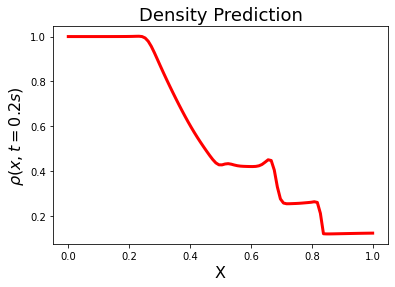

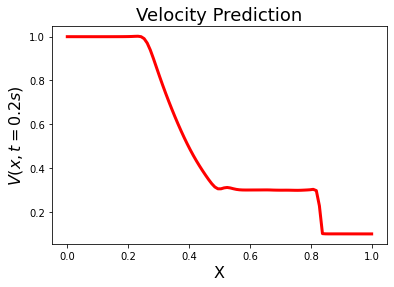

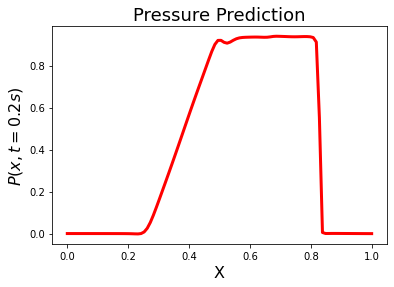

In [170]:
#print(XT_Test[9900:10000,:])
plt.plot(XT_Test[9900:10000,0],Density_Pred[9900:10000],'-',color='r',linewidth=3)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$\rho(x,t=0.2s)$",fontsize=16)
plt.title("Density Prediction",fontsize=18)
plt.show()


plt.plot(XT_Test[9900:10000,0],Velocity_Pred[9900:10000],'-',color='r',linewidth=3)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$V(x,t=0.2s)$",fontsize=16)
plt.title("Velocity Prediction",fontsize=18)
plt.show()


plt.plot(XT_Test[9900:10000,0],Pressure_Pred[9900:10000],'-',color='r',linewidth=3)
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$P(x,t=0.2s)$",fontsize=16)
plt.title("Pressure Prediction",fontsize=18)

plt.show()

---
---